## RNN Fundamentals From Scratch

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Input

np.random.seed(42)
tf.random.set_seed(42)

print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)

NumPy: 2.5.4
TensorFlow: 2.21.0


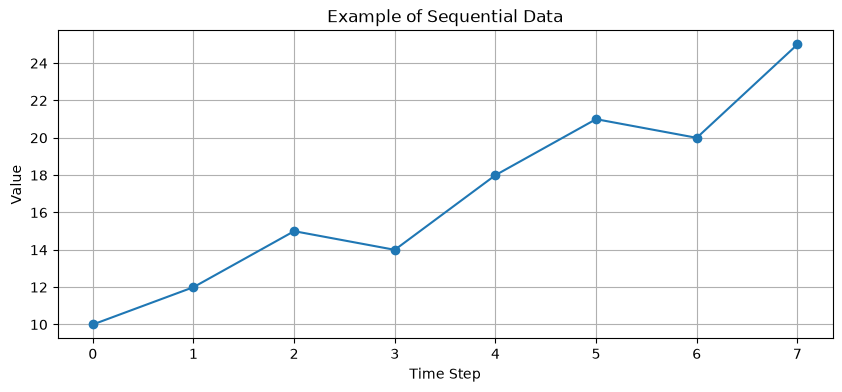

In [2]:
sequence = [10, 12, 15, 14, 18, 21, 20, 25]

plt.figure(figsize=(10, 4))
plt.plot(range(len(sequence)), sequence, marker="o")
plt.title("Example of Sequential Data")
plt.xlabel("Time Step")
plt.ylabel("Value")
plt.grid(True)
plt.show()

In [3]:
# One input feature, two hidden units, one output feature
input_size = 1
hidden_size = 2
output_size = 1

Wx = np.random.randn(hidden_size, input_size) * 0.5
Wh = np.random.randn(hidden_size, hidden_size) * 0.5
bh = np.zeros((hidden_size, 1))

Wy = np.random.randn(output_size, hidden_size) * 0.5
by = np.zeros((output_size, 1))

def rnn_cell(x_t, h_prev):
    h_t = np.tanh(Wx @ x_t + Wh @ h_prev + bh)
    y_t = Wy @ h_t + by
    return h_t, y_t

x_t = np.array([[0.7]])
h_prev = np.zeros((hidden_size, 1))

h_t, y_t = rnn_cell(x_t, h_prev)

print("Input:\n", x_t)
print("Hidden state:\n", h_t)
print("Output:\n", y_t)

Input:
 [[0.7]]
Hidden state:
 [[ 0.1721194 ]
 [-0.04835477]]
Output:
 [[0.11735202]]


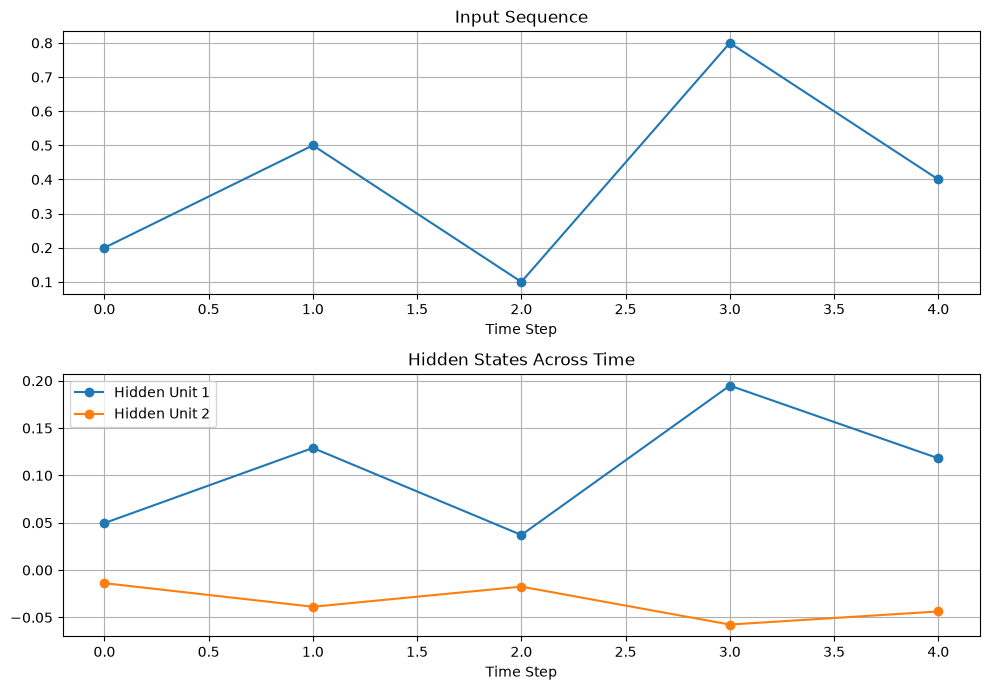

In [4]:
sequence = np.array([0.2, 0.5, 0.1, 0.8, 0.4])
hidden_states = []
outputs = []

h = np.zeros((hidden_size, 1))

for value in sequence:
    x = np.array([[value]])
    h, y = rnn_cell(x, h)

    hidden_states.append(h.flatten())
    outputs.append(y.item())

hidden_states = np.array(hidden_states)

fig, axes = plt.subplots(2, 1, figsize=(10, 7))

axes[0].plot(sequence, marker="o")
axes[0].set_title("Input Sequence")
axes[0].set_xlabel("Time Step")
axes[0].grid(True)

for i in range(hidden_size):
    axes[1].plot(hidden_states[:, i], marker="o", label=f"Hidden Unit {i+1}")

axes[1].set_title("Hidden States Across Time")
axes[1].set_xlabel("Time Step")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

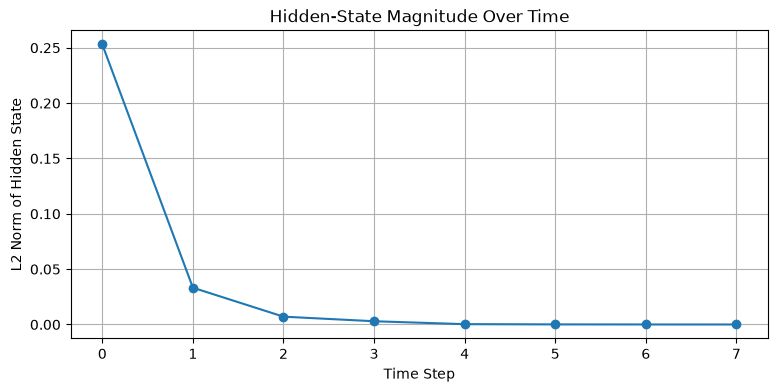

In [5]:
sequence = np.array([1, 0, 0, 0, 0, 0, 0, 0], dtype=float)

h = np.zeros((hidden_size, 1))
hidden_norms = []

for value in sequence:
    x = np.array([[value]])
    h, _ = rnn_cell(x, h)
    hidden_norms.append(np.linalg.norm(h))

plt.figure(figsize=(9, 4))
plt.plot(hidden_norms, marker="o")
plt.title("Hidden-State Magnitude Over Time")
plt.xlabel("Time Step")
plt.ylabel("L2 Norm of Hidden State")
plt.grid(True)
plt.show()

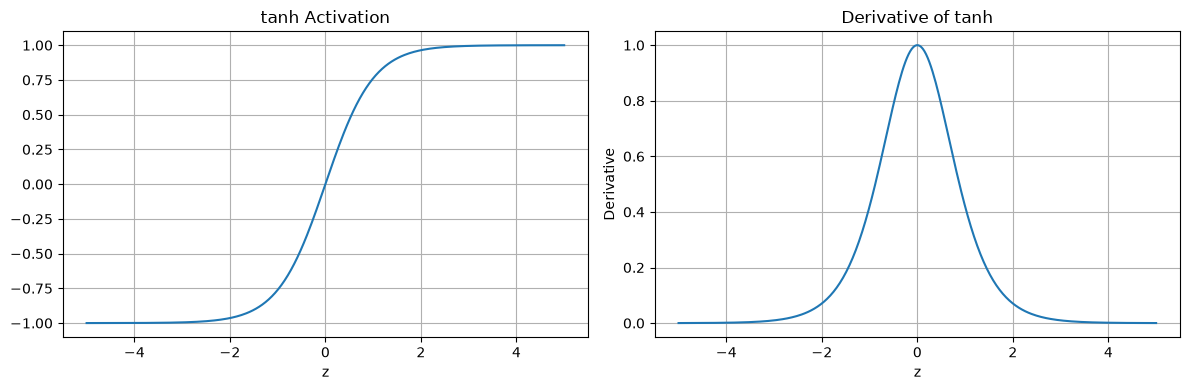

In [6]:
z_values = np.linspace(-5, 5, 300)
tanh_values = np.tanh(z_values)
tanh_derivatives = 1 - tanh_values**2

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(z_values, tanh_values)
axes[0].set_title("tanh Activation")
axes[0].set_xlabel("z")
axes[0].grid(True)

axes[1].plot(z_values, tanh_derivatives)
axes[1].set_title("Derivative of tanh")
axes[1].set_xlabel("z")
axes[1].set_ylabel("Derivative")
axes[1].grid(True)

plt.tight_layout()
plt.show()

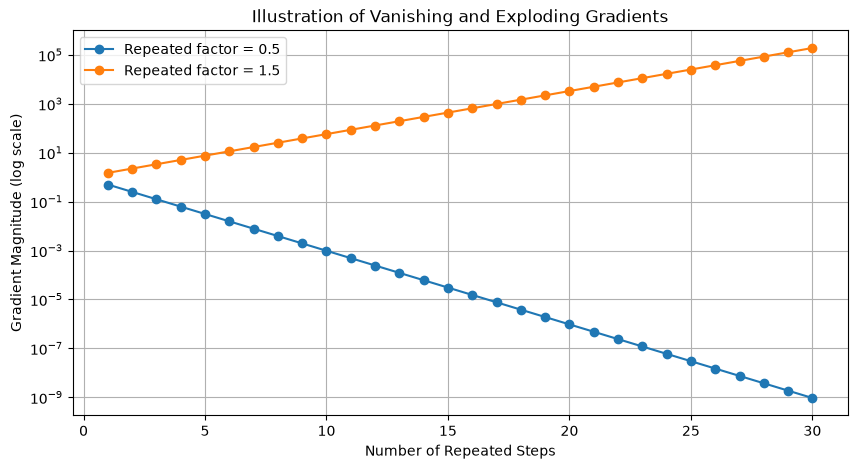

In [7]:
steps = np.arange(1, 31)

vanishing = 0.5 ** steps
exploding = 1.5 ** steps

plt.figure(figsize=(10, 5))
plt.plot(steps, vanishing, marker="o", label="Repeated factor = 0.5")
plt.plot(steps, exploding, marker="o", label="Repeated factor = 1.5")
plt.yscale("log")
plt.title("Illustration of Vanishing and Exploding Gradients")
plt.xlabel("Number of Repeated Steps")
plt.ylabel("Gradient Magnitude (log scale)")
plt.legend()
plt.grid(True)
plt.show()

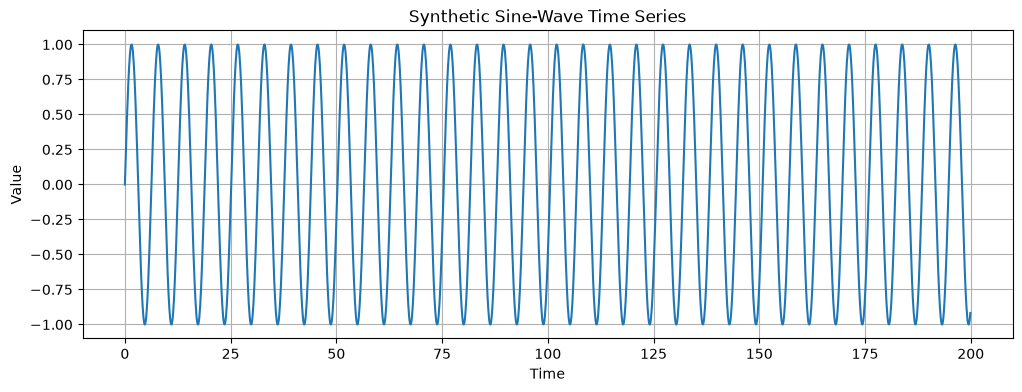

In [8]:
time = np.arange(0, 200, 0.1)
series = np.sin(time)

plt.figure(figsize=(12, 4))
plt.plot(time, series)
plt.title("Synthetic Sine-Wave Time Series")
plt.xlabel("Time")
plt.ylabel("Value")
plt.grid(True)
plt.show()

In [9]:
window_size = 20

X, y = [], []

for i in range(len(series) - window_size):
    X.append(series[i:i + window_size])
    y.append(series[i + window_size])

X = np.array(X, dtype=np.float32).reshape(-1, window_size, 1)
y = np.array(y, dtype=np.float32)

split_index = int(len(X) * 0.8)

X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1584, 20, 1)
y_train: (1584,)
X_test: (396, 20, 1)
y_test: (396,)


In [10]:
model = Sequential([
    Input(shape=(window_size, 1)),
    SimpleRNN(32, activation="tanh"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

Epoch 1/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 0.0635 - mae: 0.1582 - val_loss: 0.0051 - val_mae: 0.0605
Epoch 2/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0026 - mae: 0.0428 - val_loss: 9.5513e-04 - val_mae: 0.0268
Epoch 3/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 4.7020e-04 - mae: 0.0180 - val_loss: 2.5191e-04 - val_mae: 0.0141
Epoch 4/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2.3144e-04 - mae: 0.0136 - val_loss: 2.0653e-04 - val_mae: 0.0128
Epoch 5/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 1.9463e-04 - mae: 0.0125 - val_loss: 1.7314e-04 - val_mae: 0.0117
Epoch 6/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 1.6305e-04 - mae: 0.0114 - val_loss: 1.4443e-04 - val_mae: 0.0107
Epoch 7/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.3604e-04 - mae: 0.0104 - val_loss: 1.2011e-04 - val_mae: 0.0098
Epoch 8/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.1307e-04 - mae: 0.0095 - val_loss: 9.9639e-05 - val_mae: 0.0089
Epoch 9/15
45/45 

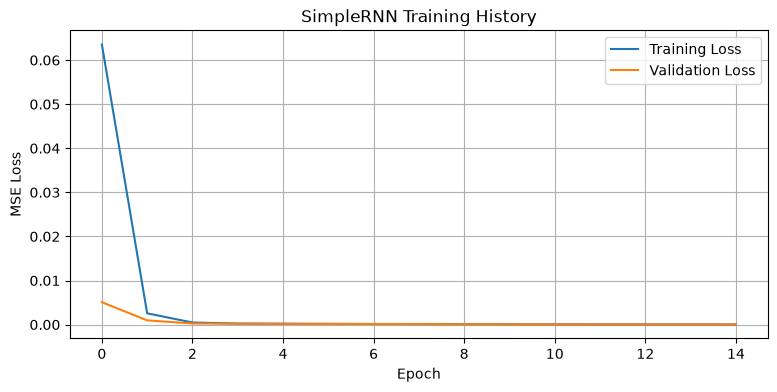

In [12]:
plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("SimpleRNN Training History")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

Test MSE: 0.000022
Test MAE: 0.004099


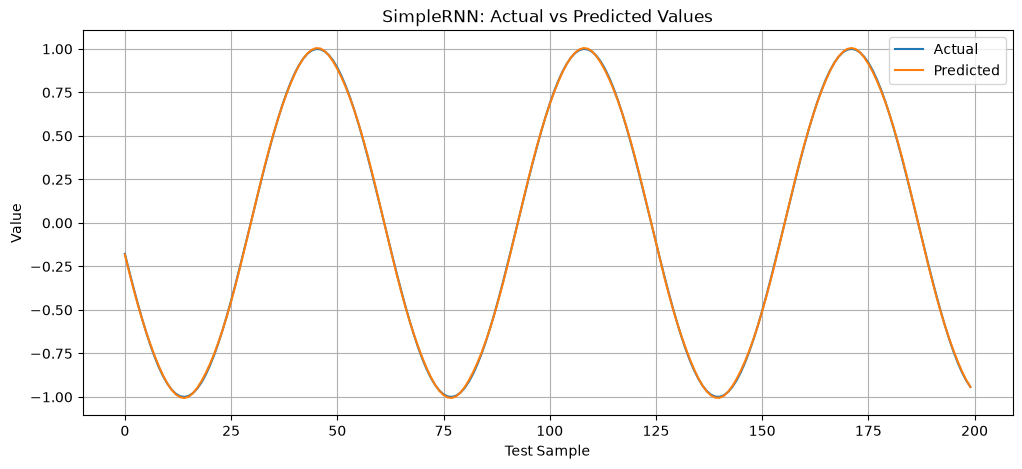

In [13]:
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)

print(f"Test MSE: {test_loss:.6f}")
print(f"Test MAE: {test_mae:.6f}")

predictions = model.predict(X_test, verbose=0).flatten()

plt.figure(figsize=(12, 5))
plt.plot(y_test[:200], label="Actual")
plt.plot(predictions[:200], label="Predicted")
plt.title("SimpleRNN: Actual vs Predicted Values")
plt.xlabel("Test Sample")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
last_window = series[-window_size:].astype(np.float32)
input_sequence = last_window.reshape(1, window_size, 1)

next_prediction = model.predict(input_sequence, verbose=0)[0, 0]

print("Last observed value:", series[-1])
print("Predicted next value:", next_prediction)

Last observed value: -0.9175720583981384
Predicted next value: -0.86418176
